# Логистика поставки: от поставщика до себестоимости рейса
*Delivery planning: order size, vehicle choice, route, fuel, trip cost, tariff and driver schedule*

**Кейс:** доставка комплекта спортивного инвентаря (850 кг, 12.5 м³) со склада в Люберцах в школу в Санкт-Петербурге.

**Что считаю:**
1. оптимальный размер заказа (EOQ);
2. выбор тягача и полуприцепа методом взвешенных оценок;
3. сравнение маршрутов;
4. использование подвижного состава и расход топлива;
5. себестоимость рейса и тариф;
6. время доставки с учётом режима труда водителя (ЕС 561/2006);
7. сверка с курсовой.

> Перенос расчётной части моей курсовой по дисциплине «Логистические системы» (МТУСИ, 2025) в Python. Каждый расчёт — функция, которую можно переиспользовать с другими цифрами.

In [1]:
import math
from datetime import datetime, timedelta
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
BLUE, ORANGE = '#2a78d6', '#eb6834'
INK, INK_2, GRID, SURFACE, NEUTRAL = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb', '#c9c8c2'
available = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({
    'font.family': 'Inter' if 'Inter' in available else 'DejaVu Sans',
    'font.size': 11, 'text.color': INK, 'axes.labelcolor': INK_2,
    'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.edgecolor': GRID, 'axes.facecolor': SURFACE, 'figure.facecolor': SURFACE,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'savefig.dpi': 150, 'savefig.bbox': 'tight',
})

## 1. Оптимальный размер заказа (EOQ)

$$EOQ = \sqrt{\frac{2DS}{H}}$$

$D$ — годовой спрос, $S$ — стоимость размещения заказа, $H$ — издержки хранения единицы в год.

In [2]:
def eoq(D, S, H):
    return math.sqrt(2 * D * S / H)

orders = pd.DataFrame({
    'D, ед./год': [1200, 500, 800],
    'S, руб.': [2000, 1800, 2200],
    'H, руб./ед.': [50, 60, 70],
}, index=['мячи', 'ракетки', 'экипировка'])

orders['EOQ, ед.'] = orders.apply(lambda r: eoq(r['D, ед./год'], r['S, руб.'], r['H, руб./ед.']), axis=1)
orders['заказов в год'] = orders['D, ед./год'] / orders['EOQ, ед.']
orders['годовые затраты, руб.'] = (orders['заказов в год'] * orders['S, руб.']
                                   + orders['EOQ, ед.'] / 2 * orders['H, руб./ед.'])
orders.round(1)

,"D, ед./год","S, руб.","H, руб./ед.","EOQ, ед.",заказов в год,"годовые затраты, руб."
мячи,1200,2000,50,309.80,3.90,"15,491.90"
ракетки,500,1800,60,173.20,2.90,"10,392.30"
экипировка,800,2200,70,224.20,3.60,"15,697.10"


## 2. Выбор подвижного состава: взвешенные оценки

Каждый вариант получает оценку от 1 до 10 по критериям, итог — сумма оценок, умноженных на веса.

In [3]:
def weighted_score(scores: pd.DataFrame, weights: pd.Series) -> pd.Series:
    assert abs(weights.sum() - 1) < 1e-9, 'веса должны давать в сумме 1'
    return scores.mul(weights, axis=0).sum().sort_values(ascending=False)

tractor_weights = pd.Series({'мощность': .20, 'расход топлива': .25, 'стоимость': .20,
                             'надёжность': .20, 'обслуживание': .15})
tractors = pd.DataFrame({
    'MAN TGX':           [9, 10, 10, 9, 8],
    'Volvo FH':          [10, 7, 6, 10, 9],
    'Mercedes Actros':   [8, 8, 8, 9, 9],
}, index=tractor_weights.index)

trailer_weights = pd.Series({'объём': .25, 'грузоподъёмность': .20, 'защита груза': .20,
                             'стоимость': .20, 'надёжность': .15})
trailers = pd.DataFrame({
    'A1 бортовой':        [8, 8, 7, 10, 8],
    'B1 тентованный':     [9, 9, 9, 8, 9],
    'C1 изотермический':  [10, 10, 10, 6, 9],
}, index=trailer_weights.index)

tractor_rank = weighted_score(tractors, tractor_weights)
trailer_rank = weighted_score(trailers, trailer_weights)
display(tractor_rank.to_frame('балл'))
display(trailer_rank.to_frame('балл'))
print(f'Выбор: {tractor_rank.index[0]} + {trailer_rank.index[0]}')

,балл
MAN TGX,9.30
Mercedes Actros,8.35
Volvo FH,8.30


,балл
C1 изотермический,9.05
B1 тентованный,8.80
A1 бортовой,8.20


Выбор: MAN TGX + C1 изотермический


## 3. Сравнение маршрутов

In [4]:
FUEL_L_PER_KM = 0.285      # 28.5 л/100 км у MAN TGX
FUEL_PRICE = 35            # руб./л
DEPRECIATION_PER_KM = 2    # руб./км

def route_cost(km, toll):
    fuel = km * FUEL_L_PER_KM * FUEL_PRICE
    return pd.Series({'км': km, 'топливо': fuel, 'платная дорога': toll,
                      'амортизация': km * DEPRECIATION_PER_KM,
                      'итого': fuel + toll + km * DEPRECIATION_PER_KM})

routes = pd.DataFrame({
    'М10 (через Тверь)': route_cost(708, 800),
    'А-118 + М9 (через Клин)': route_cost(760, 300),
}).T
routes.round(0)

,км,топливо,платная дорога,амортизация,итого
М10 (через Тверь),708.00,"7,062.00",800.00,"1,416.00","9,278.00"
А-118 + М9 (через Клин),760.00,"7,581.00",300.00,"1,520.00","9,401.00"


**Вывод.** М10 короче на 52 км и дешевле на ~120 руб., дорога лучше — выбираем её. Разница в цене небольшая, так что решают время и качество дороги.

## 4. Использование подвижного состава и расход топлива

In [5]:
q_n, G0 = 24, 6.5                 # грузоподъёмность и собственная масса полуприцепа, т
body = dict(a=13.6, b=2.5, h=2.7)  # кузов, м
cargo_t, cargo_m3, distance = 0.85, 12.5, 708

volume = body['a'] * body['b'] * body['h']
usage = pd.Series({
    'объём кузова, м³': volume,
    'объёмная грузоподъёмность, т/м³': q_n / volume,
    'коэффициент использования массы': q_n / (q_n + G0),
    'загрузка по массе, %': cargo_t / q_n * 100,
    'загрузка по объёму, %': cargo_m3 / volume * 100,
})
usage.round(3).to_frame('значение')

,значение
"объём кузова, м³",91.80
"объёмная грузоподъёмность, т/м³",0.26
коэффициент использования массы,0.79
"загрузка по массе, %",3.54
"загрузка по объёму, %",13.62


In [6]:
def fuel_litres(km, cargo_t, base=28.5, per_tonne=0.8, road_k=1.0):
    # норма: (базовый расход + надбавка на тонну груза) на 100 км, с поправкой на дорогу
    return road_k * (base + per_tonne * cargo_t) * km / 100

fuel = pd.DataFrame({
    'расход, л': [fuel_litres(distance, cargo_t), fuel_litres(distance, q_n)],
}, index=['фактический груз 0.85 т', 'полная загрузка 24 т'])
fuel['стоимость, руб.'] = fuel['расход, л'] * FUEL_PRICE
print(f'надбавка за груз: {0.8 * cargo_t / 28.5:.1%} к базовому расходу')
fuel.round(1)

надбавка за груз: 2.4% к базовому расходу


,"расход, л","стоимость, руб."
фактический груз 0.85 т,206.60,"7,230.80"
полная загрузка 24 т,337.70,"11,820.10"


**Вывод.** Груз весит 850 кг при грузоподъёмности 24 т — полуприцеп загружен на 3.5% по массе и на 14% по объёму. Для такого груза хватило бы фургона, это главный резерв экономии (см. итог).

## 5. Себестоимость рейса и тариф

In [7]:
variable = pd.Series({
    'топливо': round(fuel.iloc[0]['расход, л'], 1) * FUEL_PRICE,
    'платная дорога': 800,
    'амортизация (пробег)': distance * DEPRECIATION_PER_KM,
    'зарплата водителя': 2 * 1600,
    'питание и проживание': 2 * 600,
})

TRIPS_PER_YEAR = 60
annual_fixed = pd.Series({
    'амортизация ПС (10 лет)': 800_000,
    'управленческие расходы': 150_000,
    'техобслуживание': 120_000,
    'ОСАГО, зелёная карта': 60_000,
    'страхование рисков': 40_000,
    'налог на имущество': 30_000,
    'техосмотр': 5_000,
})
fixed_per_trip = annual_fixed / TRIPS_PER_YEAR

trip_cost = variable.sum() + fixed_per_trip.sum()
MARGIN = 0.35
tariff = trip_cost * (1 + MARGIN)

summary = pd.Series({
    'переменные затраты на рейс': variable.sum(),
    'постоянные затраты на рейс': fixed_per_trip.sum(),
    'себестоимость рейса': trip_cost,
    'себестоимость 1 т': trip_cost / cargo_t,
    'себестоимость 1 т·км': trip_cost / (cargo_t * distance),
    'тариф (наценка 35%)': tariff,
    'прибыль с рейса': tariff - trip_cost,
}, name='руб.')
summary.round(1).to_frame()

,руб.
переменные затраты на рейс,"13,847.00"
постоянные затраты на рейс,"20,083.30"
себестоимость рейса,"33,930.30"
себестоимость 1 т,"39,918.00"
себестоимость 1 т·км,56.40
тариф (наценка 35%),"45,806.00"
прибыль с рейса,"11,875.60"


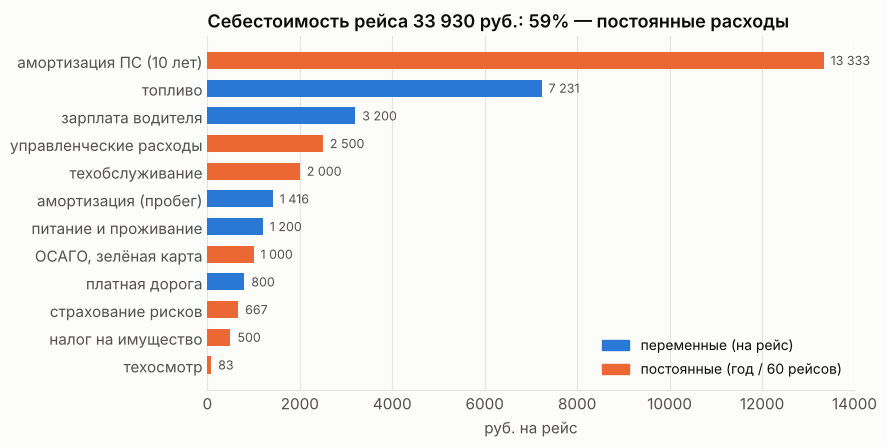

доля постоянных: 59%


In [8]:
costs = pd.concat([variable, fixed_per_trip]).sort_values()
kind = ['переменные' if k in variable.index else 'постоянные' for k in costs.index]

fig, ax = plt.subplots(figsize=(9, 4.6))
colors = [BLUE if k == 'переменные' else ORANGE for k in kind]
ax.barh(costs.index, costs.values, color=colors, height=0.62)
for i, v in enumerate(costs.values):
    ax.text(v + 150, i, f'{v:,.0f}'.replace(',', ' '), va='center', fontsize=9, color=INK_2)
ax.set_title(f'Себестоимость рейса {trip_cost:,.0f} руб.: 59% — постоянные расходы'.replace(',', ' '))
ax.set_xlabel('руб. на рейс')
ax.grid(axis='x', color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.spines['left'].set_visible(False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label='переменные (на рейс)'),
                   Patch(color=ORANGE, label='постоянные (год / 60 рейсов)')],
          frameon=False, loc='lower right', fontsize=10)
plt.tight_layout()
plt.savefig('images/trip-cost.png')
plt.show()
print(f'доля постоянных: {fixed_per_trip.sum() / trip_cost:.0%}')

## 6. Время доставки с учётом режима труда и отдыха

Правила ЕС 561/2006 для одного водителя: не больше 4.5 ч за рулём подряд, затем перерыв 45 мин, не больше 9 ч вождения в сутки, затем отдых 11 ч.
Экипаж из двух водителей сменяет друг друга, поэтому машина может ехать без перерывов — до 18 ч вождения в сутки на двоих.

Функция ниже строит расписание по этим правилам.

In [9]:
def schedule(distance_km, speed=60, start='2025-10-06 08:00', load_h=1.0, unload_h=1.5, team=False):
    t = datetime.fromisoformat(start)
    events = [('погрузка', t, t + timedelta(hours=load_h))]
    t += timedelta(hours=load_h)
    left = distance_km / speed            # часов вождения осталось
    driven_today, since_break = 0.0, 0.0
    day_limit = 18 if team else 9
    block = 4.5
    while left > 1e-9:
        if driven_today >= day_limit - 1e-9:
            events.append(('отдых', t, t + timedelta(hours=11 if not team else 9)))
            t = events[-1][2]; driven_today = since_break = 0.0
            continue
        if not team and since_break >= block - 1e-9:
            events.append(('перерыв', t, t + timedelta(minutes=45)))
            t = events[-1][2]; since_break = 0.0
            continue
        limit = min(left, day_limit - driven_today, block if not team else day_limit - driven_today)
        if not team:
            limit = min(limit, block - since_break)
        events.append(('вождение', t, t + timedelta(hours=limit)))
        t = events[-1][2]; left -= limit; driven_today += limit; since_break += limit
    events.append(('разгрузка', t, t + timedelta(hours=unload_h)))
    df = pd.DataFrame(events, columns=['этап', 'начало', 'конец'])
    df['часов'] = (df['конец'] - df['начало']).dt.total_seconds() / 3600
    return df

solo = schedule(distance)
team = schedule(distance, team=True)
for name, s in [('один водитель', solo), ('два водителя', team)]:
    total = s['конец'].iloc[-1] - s['начало'].iloc[0]
    print(f'{name}: прибытие с разгрузкой {s["конец"].iloc[-1]:%a %H:%M}, всего {total}')
solo

один водитель: прибытие с разгрузкой Tue 10:03, всего 1 days 02:03:00
два водителя: прибытие с разгрузкой Mon 22:18, всего 0 days 14:18:00


,этап,начало,конец,часов
0,погрузка,2025-10-06 08:00:00,2025-10-06 09:00:00,1.00
1,вождение,2025-10-06 09:00:00,2025-10-06 13:30:00,4.50
2,перерыв,2025-10-06 13:30:00,2025-10-06 14:15:00,0.75
3,вождение,2025-10-06 14:15:00,2025-10-06 18:45:00,4.50
4,отдых,2025-10-06 18:45:00,2025-10-07 05:45:00,11.00
5,вождение,2025-10-07 05:45:00,2025-10-07 08:33:00,2.80
6,разгрузка,2025-10-07 08:33:00,2025-10-07 10:03:00,1.50


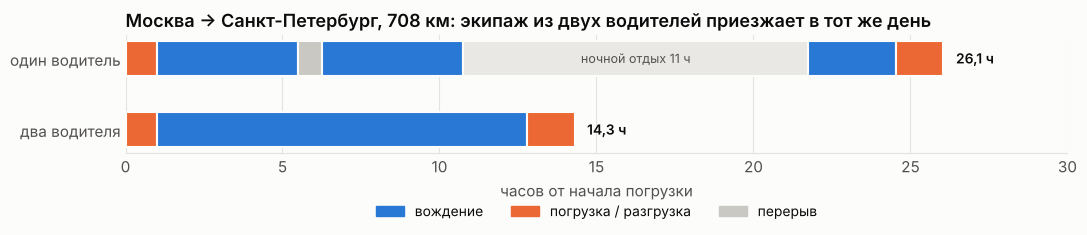

In [10]:
fig, ax = plt.subplots(figsize=(11, 2.8))
palette = {'вождение': BLUE, 'погрузка': ORANGE, 'разгрузка': ORANGE, 'перерыв': NEUTRAL, 'отдых': '#e9e8e4'}
t0 = solo['начало'].iloc[0]
for row, (label, s) in enumerate([('один водитель', solo), ('два водителя', team)]):
    for _, e in s.iterrows():
        x = (e['начало'] - t0).total_seconds() / 3600
        ax.barh(row, e['часов'], left=x, color=palette[e['этап']], height=0.5,
                edgecolor=SURFACE, linewidth=1.5)
        if e['этап'] == 'отдых':
            ax.text(x + e['часов'] / 2, row, 'ночной отдых 11 ч', ha='center', va='center', fontsize=9, color=INK_2)
    end = (s['конец'].iloc[-1] - t0).total_seconds() / 3600
    ax.text(end + 0.4, row, f'{end:.1f} ч'.replace('.', ','), va='center', fontsize=10, fontweight='semibold')
ax.set_yticks([0, 1], ['один водитель', 'два водителя'])
ax.invert_yaxis()
ax.set_xlabel('часов от начала погрузки')
ax.set_xlim(0, 30)
ax.set_title('Москва → Санкт-Петербург, 708 км: экипаж из двух водителей приезжает в тот же день')
ax.grid(axis='x', color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.spines['left'].set_visible(False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label='вождение'), Patch(color=ORANGE, label='погрузка / разгрузка'),
                   Patch(color=NEUTRAL, label='перерыв')],
          frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=3, fontsize=10)
plt.tight_layout()
plt.savefig('images/delivery-time.png')
plt.show()

## 7. Сверка с курсовой

Сравниваю результаты из текста курсовой с пересчётом. Где расходится — разбираю причину.

In [11]:
rows = [
    ('EOQ мячи', 309, orders.loc['мячи', 'EOQ, ед.']),
    ('EOQ ракетки', 245, orders.loc['ракетки', 'EOQ, ед.']),
    ('EOQ экипировка', 198, orders.loc['экипировка', 'EOQ, ед.']),
    ('балл MAN TGX', 9.15, tractor_rank['MAN TGX']),
    ('балл Volvo FH', 8.40, tractor_rank['Volvo FH']),
    ('балл Mercedes Actros', 8.40, tractor_rank['Mercedes Actros']),
    ('балл полуприцепа A1', 8.20, trailer_rank['A1 бортовой']),
    ('балл полуприцепа B1', 8.80, trailer_rank['B1 тентованный']),
    ('балл полуприцепа C1', 9.10, trailer_rank['C1 изотермический']),
    ('маршрут М10, руб.', 9278, routes.loc['М10 (через Тверь)', 'итого']),
    ('маршрут А-118 + М9, руб.', 9401, routes.loc['А-118 + М9 (через Клин)', 'итого']),
    ('объёмная грузоподъёмность', 0.261, usage['объёмная грузоподъёмность, т/м³']),
    ('коэффициент использования массы', 0.786, usage['коэффициент использования массы']),
    ('расход топлива, л', 206.4, fuel.iloc[0]['расход, л']),
    ('расход при полной загрузке, л', 245.5, fuel.iloc[1]['расход, л']),
    ('переменные затраты, руб.', 13840, variable.sum()),
    ('постоянные затраты на рейс, руб.', 20083, fixed_per_trip.sum()),
    ('себестоимость рейса, руб.', 33923, trip_cost),
    ('себестоимость 1 т·км, руб.', 56.4, summary['себестоимость 1 т·км']),
    ('тариф, руб.', 45795, tariff),
    ('прибыль с рейса, руб.', 11872, summary['прибыль с рейса']),
    ('время доставки, ч (1 водитель)', 27.75, (solo['конец'].iloc[-1] - solo['начало'].iloc[0]).total_seconds() / 3600),
]
check = pd.DataFrame(rows, columns=['показатель', 'курсовая', 'пересчёт']).set_index('показатель')
check['отклонение, %'] = (check['пересчёт'] / check['курсовая'] - 1) * 100
check['совпадает'] = check['отклонение, %'].abs() < 1
print(f'совпало {check["совпадает"].sum()} из {len(check)}')
check.round(3)

совпало 16 из 22


,курсовая,пересчёт,"отклонение, %",совпадает
показатель,,,,
EOQ мячи,309.00,309.84,0.27,True
EOQ ракетки,245.00,173.21,-29.30,False
EOQ экипировка,198.00,224.25,13.26,False
балл MAN TGX,9.15,9.30,1.64,False
балл Volvo FH,8.40,8.30,-1.19,False
балл Mercedes Actros,8.40,8.35,-0.59,True
балл полуприцепа A1,8.20,8.20,0.00,True
балл полуприцепа B1,8.80,8.80,-0.00,True
балл полуприцепа C1,9.10,9.05,-0.55,True


**Что нашлось при сверке.**

| расхождение | в курсовой | правильно | причина |
|---|---|---|---|
| EOQ ракеток и экипировки | 245 и 198 | 173 и 224 | арифметическая ошибка, формула та же |
| баллы тягачей | 9.15 / 8.40 / 8.40 | 9.30 / 8.30 / 8.35 | ошибка при суммировании; лидер не меняется |
| балл полуприцепа C1 | 9.10 | 9.05 | округление; лидер не меняется |
| расход при полной загрузке | 245.5 л | 337.7 л | надбавка за 24 т груза посчитана неверно |
| время доставки одним водителем | 27 ч 45 мин | ≈ 26 ч | последние 168 км заняли 4.5 ч вместо 2.8 ч (168 / 60) |
| экипаж из двух водителей | ночёвка, «экономия 4 ч 45 мин» | прибытие в тот же день, ≈ 14 ч | при смене водителей ночной отдых в пути не нужен |

Выбор техники, маршрута и тарифа от этих ошибок не меняется. Остальные показатели совпали.

## Итог

- **Выбор:** MAN TGX + изотермический полуприцеп, маршрут по М10.
- **Себестоимость рейса** 33 923 руб., тариф с наценкой 35% — 45 795 руб., прибыль 11 872 руб.
- **Время:** один водитель — около суток с ночёвкой, экипаж из двух — в тот же день.
- **Главный резерв:** фура загружена на 3.5% по массе. 59% себестоимости — постоянные расходы на тягач и полуприцеп, поэтому такой груз выгоднее отправлять фургоном или догружать попутными грузами.